# Praktikum Text Summarization Bahasa Indonesia — TF-IDF vs TextRank (Dataset IndoSum)
Versi ini memakai **IndoSum** (Kurniawan & Louvan, 2018)
Alur sama dengan modul: load data → summarizer TF-IDF & TextRank → ROUGE-1/2/L → error analysis → n_sentences 1/2/3.

> dataset IndoSum sudah dipecah menjadi kalimat/token, jadi tidak perlu `split_sentences` regex dan juga sudah di split berupa train,test,dev,Referensi ringkasan IndoSum rata-rata ±3 kalimat, jadi n_sentences=3 juga diuji.

In [ ]:
!pip -q install rouge-score networkx gdown

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
# Unduh IndoSum dari Google Drive (jika gagal karena kuota, unduh manual lalu upload 'indosum.tar.xz' ke Colab)
import os
if not os.path.exists('indosum.tar.xz'):
    !gdown 1OgYbPfXFAv3TbwP1Qcwt_CC9cVWSJaco -O indosum.tar.xz
!mkdir -p indosum && tar -xf indosum.tar.xz -C indosum
!find indosum -name "*.jsonl" | sort

Downloading...
From (original): https://drive.google.com/uc?id=1OgYbPfXFAv3TbwP1Qcwt_CC9cVWSJaco
From (redirected): https://drive.google.com/uc?id=1OgYbPfXFAv3TbwP1Qcwt_CC9cVWSJaco&confirm=t&uuid=fff61c7d-4c1a-4df8-957a-282ef6ff3c8a
To: /content/indosum.tar.xz
100% 96.0M/96.0M [00:01<00:00, 82.3MB/s]
indosum/indosum/dev.01.jsonl
indosum/indosum/dev.02.jsonl
indosum/indosum/dev.03.jsonl
indosum/indosum/dev.04.jsonl
indosum/indosum/dev.05.jsonl
indosum/indosum/test.01.jsonl
indosum/indosum/test.02.jsonl
indosum/indosum/test.03.jsonl
indosum/indosum/test.04.jsonl
indosum/indosum/test.05.jsonl
indosum/indosum/train.01.jsonl
indosum/indosum/train.02.jsonl
indosum/indosum/train.03.jsonl
indosum/indosum/train.04.jsonl
indosum/indosum/train.05.jsonl


In [ ]:
import re, glob, json, numpy as np, pandas as pd, networkx as nx
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from rouge_score import rouge_scorer
from IPython.display import display

def find(name):
    hits = glob.glob(f'indosum/**/{name}', recursive=True)
    assert hits, f'{name} tidak ditemukan'
    return hits[0]

def to_text(s):                      # kalimat bisa berupa list token atau string
    return ' '.join(s) if isinstance(s, list) else str(s)

def read_jsonl(path):
    rows = []
    with open(path, encoding='utf-8') as f:
        for line in f:
            d = json.loads(line)
            sents = [to_text(s) for p in d['paragraphs'] for s in p]
            summ  = [to_text(s) for s in d['summary']]
            rows.append({'id': d['id'], 'topic': d.get('category', '-'),
                         'sentences': sents,
                         'article': ' '.join(sents),
                         'reference_summary': ' '.join(summ)})
    return pd.DataFrame(rows)

FOLD = '01'
train_df = read_jsonl(find(f'train.{FOLD}.jsonl'))
val_df   = read_jsonl(find(f'dev.{FOLD}.jsonl'))
test_df  = read_jsonl(find(f'test.{FOLD}.jsonl'))
print('Train', len(train_df), 'Val', len(val_df), 'Test', len(test_df))
display(train_df[['id','topic','article','reference_summary']].head())
print(train_df.topic.value_counts())
print('Rata2 jumlah kalimat artikel:', train_df.sentences.map(len).mean())

Train 14262 Val 750 Test 3762


,id,topic,article,reference_summary
0,1501893029-lula-kamal-dokter-ryan-thamrin-saki...,tajuk utama,"Jakarta , CNN Indonesia - - Dokter Ryan Thamri...",Dokter Lula Kamal yang merupakan selebriti sek...
1,1509072914-dua-smartphone-zenfone-baru-tawarka...,teknologi,Selfie ialah salah satu tema terpanas di kalan...,Asus memperkenalkan ZenFone generasi keempat...
2,1510613677-songsong-visit-2020-bengkulu-perkua...,hiburan,"Jakarta , CNN Indonesia - - Dinas Pariwisata P...",Dinas Pariwisata Provinsi Bengkulu kembali men...
3,1502706803-icw-ada-kejanggalan-atas-tewasnya-s...,tajuk utama,Merdeka.com - Indonesia Corruption Watch ( ICW...,Indonesia Corruption Watch ( ICW ) meminta Kom...
4,1503039338-pembagian-sepeda-usai-upacara-penur...,tajuk utama,Merdeka.com - Presiden Joko Widodo ( Jokowi ) ...,Jokowi memimpin upacara penurunan bendera . Us...


topic
tajuk utama    5454
olahraga       3624
showbiz        1982
teknologi      1734
hiburan        1372
inspirasi        96
Name: count, dtype: int64
Rata2 jumlah kalimat artikel: 18.42483522647595


### ### Preprocessing Tambahan: Pengunduhan Stopword Bahasa Indonesia
Untuk meningkatkan kualitas tokenisasi dan pembobotan pada model TF-IDF dan TextRank, kita mengunduh kamus kata tidak penting (stopword) bahasa Indonesia berikut sebelum melangkah ke pemodelan.

In [ ]:
import urllib.request

# Unduh daftar stopword bahasa Indonesia standar
stopword_url = "https://raw.githubusercontent.com/masdevid/ID-Stopwords/master/id.stopwords.02.01.2016.txt"
with urllib.request.urlopen(stopword_url) as response:
    stopwords_list = response.read().decode('utf-8').splitlines()

print(f"Berhasil memuat {len(stopwords_list)} stopword bahasa Indonesia untuk tahap preprocessing.")
print("Contoh kata:", stopwords_list[:10])

Berhasil memuat 758 stopword bahasa Indonesia untuk tahap preprocessing.
Contoh kata: ['ada', 'adalah', 'adanya', 'adapun', 'agak', 'agaknya', 'agar', 'akan', 'akankah', 'akhir']


## Summarizer (n_sentences dapat diubah)

In [ ]:
def summarize_tfidf(sents, n_sentences=1):
    if len(sents) <= n_sentences: return ' '.join(sents)
    try:
        # Integrasikan daftar stopword bahasa Indonesia yang sudah diunduh
        X = TfidfVectorizer(lowercase=True, stop_words=stopwords_list).fit_transform(sents)
        scores = np.asarray(X.sum(axis=1)).ravel()
    except ValueError:               # vocabulary kosong -> fallback lead
        scores = -np.arange(len(sents))
    idx = sorted(np.argsort(scores)[-n_sentences:])
    return ' '.join(sents[i] for i in idx)

def summarize_textrank(sents, n_sentences=1):
    if len(sents) <= n_sentences: return ' '.join(sents)
    try:
        # Integrasikan daftar stopword bahasa Indonesia yang sudah diunduh
        X = TfidfVectorizer(lowercase=True, stop_words=stopwords_list).fit_transform(sents)
        scores = nx.pagerank(nx.from_numpy_array(cosine_similarity(X)))
    except Exception:                 # graph tanpa edge / gagal konvergen -> fallback lead
        scores = {i: -i for i in range(len(sents))}
    idx = sorted(sorted(scores, key=scores.get, reverse=True)[:n_sentences])
    return ' '.join(sents[i] for i in idx)

def summarize_lead(sents, n_sentences=1):   # baseline tambahan
    return ' '.join(sents[:n_sentences])

scorer = rouge_scorer.RougeScorer(['rouge1','rouge2','rougeL'], use_stemmer=False)

def evaluate(data, fn, n=1):
    out = []
    for _, r in data.iterrows():
        pred = fn(r['sentences'], n)
        s = scorer.score(r['reference_summary'], pred)
        out.append({'id': r['id'], 'topic': r['topic'], 'article': r['article'],
                    'prediction': pred, 'reference': r['reference_summary'],
                    'rouge1': s['rouge1'].fmeasure, 'rouge2': s['rouge2'].fmeasure,
                    'rougeL': s['rougeL'].fmeasure})
    return pd.DataFrame(out)

# Contoh satu artikel
sample = test_df.iloc[0]
print('ARTIKEL:\n', sample.article[:800], '...')
print('\nREFERENSI:\n', sample.reference_summary)
print('\nTF-IDF (with Stopwords):\n', summarize_tfidf(sample.sentences))
print('\nTextRank (with Stopwords):\n', summarize_textrank(sample.sentences))

ARTIKEL:
 Jakarta , CNN Indonesia - - Dilansir AFP , seorang warga Mesir yang dipercaya sebagai wanita terberat di dunia masuk sebuah rumah sakit di Abu Dhabi Kamis ( 5 / 5 ) , dimana ia akan melanjutkan perawatan setelah menjalankan operasi menurunkan badan di India . Eman Ahmed Abd El Aty memiliki berat badan mencapai 500 kilogram sebelum menjalankan operasi di Mumbai Maret lalu dimana ia mengurangi seperlima dari berat badannya . Ia menderita berbagai macam masalah kesehatan termasuk penyakit gajah , kondisi yang menyebabkan anggota badan membengkak . Abd El Aty diberi diet cairan khusus selama berada di India yang bertujuan menurunkan berat badan . Diet ini memungkinkan dokter melakukan operasi bariatrik , prosedur bypass yang kini sering dilakukan di India dalam menghadapi masalah obesitas yang ...

REFERENSI:
 Eman Ahmed Abd El Aty memiliki berat badan mencapai 500 kilogram sebelum menjalankan operasi di Mumbai Maret lalu dimana ia mengurangi seperlima dari berat badannya . Abd E

/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:402: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['baiknya', 'berkali', 'kali', 'kurangnya', 'mata', 'olah', 'sekurang', 'setidak', 'tama', 'tidaknya'] not in stop_words.
  warnings.warn(


## Perbandingan TF-IDF vs TextRank (n_sentences = 1, 2, 3)

In [ ]:
methods = {'TF-IDF': summarize_tfidf, 'TextRank': summarize_textrank, 'Lead-N (baseline)': summarize_lead}
results, rows = {}, []
for n in (1, 2, 3):
    for name, fn in methods.items():
        df_ = evaluate(test_df, fn, n)
        results[(name, n)] = df_
        rows.append({'n_sentences': n, 'Model': name, 'ROUGE-1': df_.rouge1.mean(),
                     'ROUGE-2': df_.rouge2.mean(), 'ROUGE-L': df_.rougeL.mean()})
comparison = pd.DataFrame(rows)
display(comparison.round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:402: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['baiknya', 'berkali', 'kali', 'kurangnya', 'mata', 'olah', 'sekurang', 'setidak', 'tama', 'tidaknya'] not in stop_words.
  warnings.warn(


,n_sentences,Model,ROUGE-1,ROUGE-2,ROUGE-L
0,1,TF-IDF,0.3255,0.2424,0.2927
1,1,TextRank,0.2809,0.1889,0.2464
2,1,Lead-N (baseline),0.4031,0.3590,0.3901
3,2,TF-IDF,0.4297,0.3234,0.3796
4,2,TextRank,0.3941,0.2682,0.3329
5,2,Lead-N (baseline),0.5800,0.5202,0.5561
6,3,TF-IDF,0.4626,0.3528,0.4060
7,3,TextRank,0.4375,0.3065,0.3678
8,3,Lead-N (baseline),0.6524,0.5846,0.6220


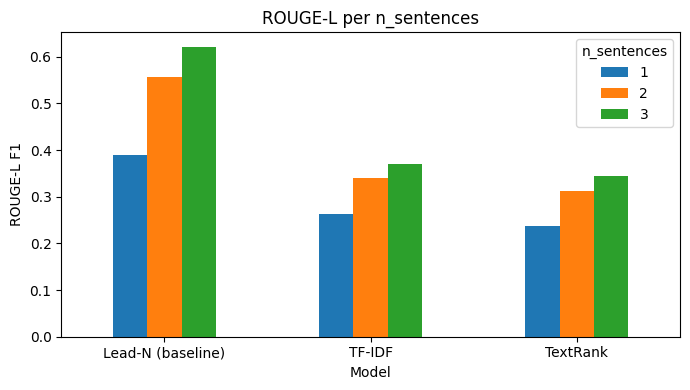

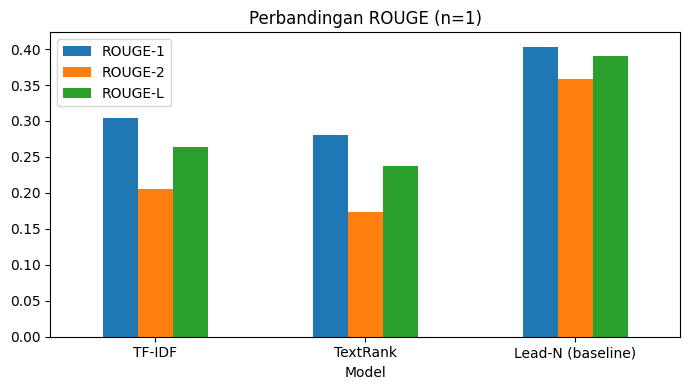

In [ ]:
piv = comparison.pivot(index='Model', columns='n_sentences', values='ROUGE-L')
piv.plot(kind='bar', figsize=(7,4)); plt.ylabel('ROUGE-L F1'); plt.title('ROUGE-L per n_sentences')
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

c1 = comparison[comparison.n_sentences==1].set_index('Model')[['ROUGE-1','ROUGE-2','ROUGE-L']]
c1.plot(kind='bar', figsize=(7,4)); plt.title('Perbandingan ROUGE (n=1)'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## Analisis prediksi terbaik dan terburuk

In [ ]:
r1 = results[('TF-IDF', 1)]; r2 = results[('TextRank', 1)]
show = ['id','topic','prediction','reference','rougeL']
pd.set_option('display.max_colwidth', 200)
print('Terbaik TF-IDF');     display(r1.sort_values('rougeL', ascending=False).head(3)[show])
print('Terburuk TF-IDF');    display(r1.sort_values('rougeL').head(3)[show])
print('Terbaik TextRank');   display(r2.sort_values('rougeL', ascending=False).head(3)[show])
print('Terburuk TextRank');  display(r2.sort_values('rougeL').head(3)[show])
print('Per kategori (n=1)')
display(pd.concat({'TF-IDF': r1.groupby('topic').rougeL.mean(),
                   'TextRank': r2.groupby('topic').rougeL.mean()}, axis=1).round(4))

Terbaik TF-IDF


,id,topic,prediction,reference,rougeL
1024,1516929300-tabir-surya-ternyata-juga-diperlukan-saat-naik-pes,hiburan,"Jakarta ( ANTARA News ) - Sebagian orang mengira tabir surya hanya perlu digunakan saat cuaca terik , tapi ahli dermatologi mengatakan bahwa krim pelindung kulit ini harus digunakan setiap hari , ...","Sebagian orang mengira tabir surya hanya perlu digunakan saat cuaca terik , tapi ahli dermatologi mengatakan bahwa krim pelindung kulit ini harus digunakan setiap hari , termasuk saat bepergian na...",0.913386
2765,1506032245-moto-g5s-plus-siap-gempur-segmen-menengah,teknologi,"Moto GS5 Plus dipersenjatai system-on-chip Qualcomm kelas mid - high Snapdragon 625 yang menyimpan CPU octa-core Cortex - A53 2 GHz dan GPU Adreno 506 , juga ditunjang RAM 4 GB , penyimpanan inter...",Motorola resmi memperkenalkan Moto G5S Plus di tanah air . Ponsel ini dipersenjatai system-on-chip Qualcomm kelas mid - high Snapdragon 625 dengan CPU octa-core Cortex - A53 2 GHz dan GPU Adreno 5...,0.902256
691,1498969800-kisah-para-pesepakbola-yang-selamat-dari-maut-di-u,olahraga,"Seperti halnya para pesepakbola yang selamat dari tragedi Superga Air Disaster 1949 ( Torino ) , Munich Air Disaster 1958 ( Manchester United ) , dan yang terbaru kecelakaan pesawat yang menimpa k...","Bagi sebagian orang , tertundanya keberangkatan pesawat , dapat menjadi berkah tersendiri . Seperti halnya para pesepakbola yang selamat dari tragedi Superga Air Disaster 1949 ( Torino ) , Munich ...",0.897959


Terburuk TF-IDF


,id,topic,prediction,reference,rougeL
1782,1517421600-hasil-arema-fc-vs-bhayangkara-fc,olahraga,"Panggih Prio Sembodo , Vladimir Vujovic , Jajang Mulyana , Alsan Putra Masat Sanda , I Putu Gede Juniantara , Lee Hyo Joon , Muhammad Hargianto , T.M Ichsan , Paulo Sergio , Marinus Mariyanto Mane...",Arema FC memastikan satu tiket tersisa ke babak delapan besar Piala Presiden . Kepastian tersebut didapatkan setelah mereka menahan tanpa gol Bhayangkara FC pada laga pamungkas Grup E di Stadion K...,0.0
1348,1492623003-pemilihan-presiden-korsel-semua-acara-musik-dibata,tajuk utama,"Geun Hye dicopot dari kursi kepresidenan setelah kedapatan membantu Choi Soon Sil , kerabat dekatnya , menekan sejumlah konglomerat Korsel menggelontorkan jutaan dolar uang bagi dua yayasan pribadi .","Korea Selatan tak akan menayangkan acara musik di pekan pertama Mei . Semua jadwal pertunjukan di waktu tersebut diminta untuk dibatalkan . Melansir Soompi , semua pertunjukan musik yang disiarkan...",0.0
195,1489540518-bahas-ekonomi-jokowi-panggil-seluruh-bos-lembaga-n,tajuk utama,"Ia mengimbau kepada warga khususnya yang tinggal di daerah pesisir agar tidak panik dengan adanya gempa tersebut , tapi harus tetap waspada karena bisa saja gempa susulan dengan kekuatan yang lebi...","Presiden Jokowi memanggil seluruh kepala lembaga tinggi negara siang ini , untuk membahas soal ekonomi . Pimpinan DPR dan MPR bersama pimpinan DPD . Hadir Ketua MA Hatta Ali , Wakil Ketua MK Anwar...",0.0


Terbaik TextRank


,id,topic,prediction,reference,rougeL
1024,1516929300-tabir-surya-ternyata-juga-diperlukan-saat-naik-pes,hiburan,"Jakarta ( ANTARA News ) - Sebagian orang mengira tabir surya hanya perlu digunakan saat cuaca terik , tapi ahli dermatologi mengatakan bahwa krim pelindung kulit ini harus digunakan setiap hari , ...","Sebagian orang mengira tabir surya hanya perlu digunakan saat cuaca terik , tapi ahli dermatologi mengatakan bahwa krim pelindung kulit ini harus digunakan setiap hari , termasuk saat bepergian na...",0.913386
3721,1489957238-diet-mediterinia-hasilkan-sperma-berkualitas-tingg,hiburan,"Jakarta , CNN Indonesia - - Sebuah penelitian terbaru menyebutkan kualitas sperma pria bertambah bagus jika ia menjalani diet Mediterania yang kaya dengan buah , sayur , ikan , susu rendah kalori ...","Sebuah penelitian terbaru menyebutkan kualitas sperma pria bertambah bagus jika ia menjalani diet Mediterania yang kaya dengan buah , sayur , ikan , susu rendah kalori dan seorang pria dapat mengi...",0.872727
3760,1519078335-pn-depok-gelar-sidang-perdana-kasus-first-travel,tajuk utama,"Jakarta , CNN Indonesia - - Pengadilan Negeri Depok akan menggelar sidang kasus penipuan dan penggelapan dana jamaah umrah First Travel dengan tiga terdakwa , yakni Direktur Utama First Travel And...","Pengadilan Negeri Depok akan menggelar sidang kasus penipuan dan penggelapan dana jamaah umrah First Travel dengan tiga terdakwa , yakni Direktur Utama First Travel Andika Surachman , Direktur Fir...",0.842105


Terburuk TextRank


,id,topic,prediction,reference,rougeL
1333,1515648046-yasonna-laoly-penuhi-panggilan-kpk,tajuk utama,"Menurut dakwaan terhadap kedua mantan pejabat itu , Olly , mantan Wakil Ketua Banggar DPR dari Fraksi PDI - Perjuangan yang saat ini menjabat Gubernur Sulawesi Utara , menerima sejumlah 1,2 juta d...",Menteri Hukum dan Hak Asasi Manusia Yasonna Laoly memenuhi panggilan Komisi Pemberantasan Korupsi ( KPK ) untuk menjalani pemeriksaan sebagai saksi dalam penyidikan kasus korupsi dalam pengadaan p...,0.0
722,1508035774-ibunda-buka-suara-soal-rumor-lamaran-nikita-willy,showbiz,""" Enggak .","Aktris Nikita Willy dirumorkan baru dilamar sang kekasih , Indra Priawan Djokosoetono . Isu tersebut ramai salah satu sahabat dekat pemain film "" The Total Chaos "" , Bella Bhakty , mengabadikan mo...",0.0
195,1489540518-bahas-ekonomi-jokowi-panggil-seluruh-bos-lembaga-n,tajuk utama,"Yana menyebutkan , getaran gempa tersebut dirasakan warga di beberapa daerah di Kabupaten Sukabumi baik yang berada di wilayah selatan maupun utara .","Presiden Jokowi memanggil seluruh kepala lembaga tinggi negara siang ini , untuk membahas soal ekonomi . Pimpinan DPR dan MPR bersama pimpinan DPD . Hadir Ketua MA Hatta Ali , Wakil Ketua MK Anwar...",0.0


Per kategori (n=1)


,TF-IDF,TextRank
topic,,
hiburan,0.2249,0.2315
inspirasi,0.1830,0.2484
olahraga,0.2827,0.2150
showbiz,0.2341,0.2161
tajuk utama,0.2853,0.2601
teknologi,0.2201,0.2365


In [ ]:
# Bantuan error analysis: posisi kalimat terpilih & panjangnya
def pos_len(df_, data):
    pos, ln = [], []
    for (_, r), (_, d) in zip(df_.iterrows(), data.iterrows()):
        sents = d['sentences']
        pos.append(sents.index(r['prediction']) if r['prediction'] in sents else -1)
        ln.append(len(r['prediction'].split()))
    return pd.Series(pos), pd.Series(ln)
for name, df_ in [('TF-IDF', r1), ('TextRank', r2)]:
    p, l = pos_len(df_, test_df)
    print(f'{name}: posisi rata-rata kalimat terpilih = {p.mean():.2f}, % kalimat ke-1 = {(p==0).mean()*100:.1f}%, panjang rata-rata = {l.mean():.1f} kata')
print('Panjang rata-rata referensi:', test_df.reference_summary.str.split().str.len().mean())

TF-IDF: posisi rata-rata kalimat terpilih = 6.60, % kalimat ke-1 = 17.5%, panjang rata-rata = 37.7 kata
TextRank: posisi rata-rata kalimat terpilih = 7.33, % kalimat ke-1 = 11.7%, panjang rata-rata = 25.9 kata
Panjang rata-rata referensi: 67.66002126528443


## Perbandingan tambahan sesuai Tugas Lanjutan Pertemuan 11
Aspek: (a) waktu proses, (b) konsistensi pemilihan kalimat, (c) kemampuan mempertahankan informasi penting, (d) analisis error terstruktur.

In [ ]:
import time
# (a) WAKTU PROSES — n=1 dan n=3, seluruh test set
rows = []
for n in (1, 3):
    for name, fn in methods.items():
        t0 = time.perf_counter()
        for s_ in test_df.sentences: fn(s_, n)
        tot = time.perf_counter() - t0
        rows.append({'Model': name, 'n_sentences': n, 'Total (detik)': tot,
                     'ms / artikel': tot / len(test_df) * 1000})
time_df = pd.DataFrame(rows); display(time_df.round(3))

,Model,n_sentences,Total (detik),ms / artikel
0,TF-IDF,1,9.968,2.650
1,TextRank,1,16.548,4.399
2,Lead-N (baseline),1,0.003,0.001
3,TF-IDF,3,6.839,1.818
4,TextRank,3,16.730,4.447
5,Lead-N (baseline),3,0.004,0.001


Kedua model memilih kalimat yang SAMA : 15.8% artikel
TF-IDF    | posisi rata-rata=6.60 | % kalimat ke-1=17.5% | std ROUGE-L=0.223 | % ROUGE-L<0.1=29.2%
TextRank  | posisi rata-rata=7.33 | % kalimat ke-1=11.7% | std ROUGE-L=0.182 | % ROUGE-L<0.1=22.0%


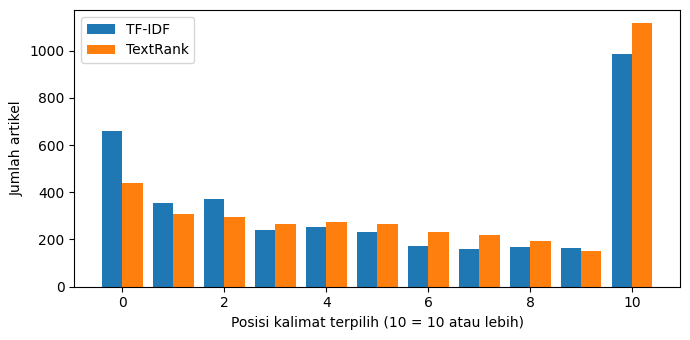

In [ ]:
# (b) KONSISTENSI PEMILIHAN KALIMAT (n=1)
def sel_pos(df_):
    pos = []
    for (_, r), s_ in zip(df_.iterrows(), test_df.sentences):
        pos.append(s_.index(r['prediction']) if r['prediction'] in s_ else -1)
    return np.array(pos)

p_tfidf, p_tr = sel_pos(r1), sel_pos(r2)
print(f'Kedua model memilih kalimat yang SAMA : {(p_tfidf == p_tr).mean()*100:.1f}% artikel')
for name, p, d in [('TF-IDF', p_tfidf, r1), ('TextRank', p_tr, r2)]:
    print(f'{name:9s} | posisi rata-rata={p.mean():.2f} | % kalimat ke-1={(p==0).mean()*100:.1f}% '
          f'| std ROUGE-L={d.rougeL.std():.3f} | % ROUGE-L<0.1={(d.rougeL<0.1).mean()*100:.1f}%')
plt.figure(figsize=(7,3.5))
bins = np.arange(0, 12) - 0.5
plt.hist([np.clip(p_tfidf,0,10), np.clip(p_tr,0,10)], bins=bins, label=['TF-IDF','TextRank'])
plt.xlabel('Posisi kalimat terpilih (10 = 10 atau lebih)'); plt.ylabel('Jumlah artikel'); plt.legend(); plt.tight_layout(); plt.show()

In [ ]:
# (c) INFORMASI PENTING: precision / recall / F1 + cakupan kata isi referensi
def pr_eval(fn, n):
    P, R, F, COV = [], [], [], []
    for _, r in test_df.iterrows():
        pred = fn(r['sentences'], n)
        sc = scorer.score(r['reference_summary'], pred)
        P.append(sc['rouge1'].precision); R.append(sc['rouge1'].recall); F.append(sc['rouge1'].fmeasure)
        ref_w = {w for w in re.findall(r'\w+', r['reference_summary'].lower()) if len(w) > 3}
        pred_w = set(re.findall(r'\w+', pred.lower()))
        COV.append(len(ref_w & pred_w) / len(ref_w) if ref_w else 0)
    return np.mean(P), np.mean(R), np.mean(F), np.mean(COV)

rows = []
for n in (1, 2, 3):
    for name, fn in methods.items():
        P, R, F, COV = pr_eval(fn, n)
        rows.append({'Model': name, 'n': n, 'ROUGE-1 P': P, 'ROUGE-1 R': R, 'ROUGE-1 F1': F, 'Cakupan kata isi ref.': COV})
pr_df = pd.DataFrame(rows); display(pr_df.round(4))

,Model,n,ROUGE-1 P,ROUGE-1 R,ROUGE-1 F1,Cakupan kata isi ref.
0,TF-IDF,1,0.4486,0.2349,0.3041,0.2545
1,TextRank,1,0.5305,0.1992,0.2808,0.2172
2,Lead-N (baseline),1,0.7559,0.2847,0.4031,0.3304
3,TF-IDF,2,0.4157,0.4027,0.4042,0.4139
4,TextRank,2,0.4679,0.3384,0.3832,0.3374
5,Lead-N (baseline),2,0.7338,0.4979,0.5800,0.5328
6,TF-IDF,3,0.3836,0.5253,0.4386,0.5265
7,TextRank,3,0.4193,0.4421,0.4215,0.4286
8,Lead-N (baseline),3,0.6741,0.6560,0.6524,0.6723


In [ ]:
# (d) ERROR ANALYSIS TERSTRUKTUR: pilih 3 kasus terburuk tiap model, tampilkan data pendukung kategori error
def error_view(df_, k=3):
    w = df_.sort_values('rougeL').head(k).copy()
    w['panjang_pred(kata)'] = w.prediction.str.split().str.len()
    w['panjang_ref(kata)'] = w.reference.str.split().str.len()
    w['overlap_kata'] = [len(set(a.lower().split()) & set(b.lower().split())) for a, b in zip(w.prediction, w.reference)]
    return w[['id','topic','prediction','reference','rougeL','panjang_pred(kata)','panjang_ref(kata)','overlap_kata']]
print('TF-IDF'); display(error_view(r1))
print('TextRank'); display(error_view(r2))
print('Kategori: tidak mewakili topik | lexical mismatch | referensi abstraktif | kalimat panjang | keterbatasan satu kalimat')

TF-IDF


,id,topic,prediction,reference,rougeL,panjang_pred(kata),panjang_ref(kata),overlap_kata
1782,1517421600-hasil-arema-fc-vs-bhayangkara-fc,olahraga,"Panggih Prio Sembodo , Vladimir Vujovic , Jajang Mulyana , Alsan Putra Masat Sanda , I Putu Gede Juniantara , Lee Hyo Joon , Muhammad Hargianto , T.M Ichsan , Paulo Sergio , Marinus Mariyanto Mane...",Arema FC memastikan satu tiket tersisa ke babak delapan besar Piala Presiden . Kepastian tersebut didapatkan setelah mereka menahan tanpa gol Bhayangkara FC pada laga pamungkas Grup E di Stadion K...,0.0,42,71,2
1348,1492623003-pemilihan-presiden-korsel-semua-acara-musik-dibata,tajuk utama,"Geun Hye dicopot dari kursi kepresidenan setelah kedapatan membantu Choi Soon Sil , kerabat dekatnya , menekan sejumlah konglomerat Korsel menggelontorkan jutaan dolar uang bagi dua yayasan pribadi .","Korea Selatan tak akan menayangkan acara musik di pekan pertama Mei . Semua jadwal pertunjukan di waktu tersebut diminta untuk dibatalkan . Melansir Soompi , semua pertunjukan musik yang disiarkan...",0.0,29,65,2
195,1489540518-bahas-ekonomi-jokowi-panggil-seluruh-bos-lembaga-n,tajuk utama,"Ia mengimbau kepada warga khususnya yang tinggal di daerah pesisir agar tidak panik dengan adanya gempa tersebut , tapi harus tetap waspada karena bisa saja gempa susulan dengan kekuatan yang lebi...","Presiden Jokowi memanggil seluruh kepala lembaga tinggi negara siang ini , untuk membahas soal ekonomi . Pimpinan DPR dan MPR bersama pimpinan DPD . Hadir Ketua MA Hatta Ali , Wakil Ketua MK Anwar...",0.0,35,73,2


TextRank


,id,topic,prediction,reference,rougeL,panjang_pred(kata),panjang_ref(kata),overlap_kata
1333,1515648046-yasonna-laoly-penuhi-panggilan-kpk,tajuk utama,"Menurut dakwaan terhadap kedua mantan pejabat itu , Olly , mantan Wakil Ketua Banggar DPR dari Fraksi PDI - Perjuangan yang saat ini menjabat Gubernur Sulawesi Utara , menerima sejumlah 1,2 juta d...",Menteri Hukum dan Hak Asasi Manusia Yasonna Laoly memenuhi panggilan Komisi Pemberantasan Korupsi ( KPK ) untuk menjalani pemeriksaan sebagai saksi dalam penyidikan kasus korupsi dalam pengadaan p...,0.0,35,62,2
722,1508035774-ibunda-buka-suara-soal-rumor-lamaran-nikita-willy,showbiz,""" Enggak .","Aktris Nikita Willy dirumorkan baru dilamar sang kekasih , Indra Priawan Djokosoetono . Isu tersebut ramai salah satu sahabat dekat pemain film "" The Total Chaos "" , Bella Bhakty , mengabadikan mo...",0.0,3,74,2
195,1489540518-bahas-ekonomi-jokowi-panggil-seluruh-bos-lembaga-n,tajuk utama,"Yana menyebutkan , getaran gempa tersebut dirasakan warga di beberapa daerah di Kabupaten Sukabumi baik yang berada di wilayah selatan maupun utara .","Presiden Jokowi memanggil seluruh kepala lembaga tinggi negara siang ini , untuk membahas soal ekonomi . Pimpinan DPR dan MPR bersama pimpinan DPD . Hadir Ketua MA Hatta Ali , Wakil Ketua MK Anwar...",0.0,23,73,2


Kategori: tidak mewakili topik | lexical mismatch | referensi abstraktif | kalimat panjang | keterbatasan satu kalimat


##  Perbandingan dengan model abstractive
Model: **mT5 yang di-fine-tune pada XL-Sum multibahasa** (`csebuetnlp/mT5_multilingual_XLSum`, mencakup bahasa Indonesia), dipakai apa adanya (zero-shot terhadap IndoSum, tanpa fine-tuning). Memakai sampel 50 artikel test agar cepat.

In [ ]:
!pip -q install transformers sentencepiece accelerate

In [ ]:
import torch, time
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
MODEL = 'csebuetnlp/mT5_multilingual_XLSum'
tok = AutoTokenizer.from_pretrained(MODEL)
mdl = AutoModelForSeq2SeqLM.from_pretrained(MODEL).to('cuda' if torch.cuda.is_available() else 'cpu')

sub = test_df.sample(50, random_state=42).reset_index(drop=True)
abs_preds, t0 = [], time.perf_counter()
for a in sub.article:
    ids = tok(a, return_tensors='pt', truncation=True, max_length=512).to(mdl.device)
    with torch.no_grad():
        out = mdl.generate(**ids, max_length=84, num_beams=4, no_repeat_ngram_size=2)
    abs_preds.append(tok.decode(out[0], skip_special_tokens=True))
abs_time = (time.perf_counter() - t0) / len(sub) * 1000

def score_preds(preds, refs):
    sc = [scorer.score(r, p) for r, p in zip(refs, preds)]
    return {m: np.mean([x[m].fmeasure for x in sc]) for m in ('rouge1','rouge2','rougeL')}

rows = []
for name, fn, n in [('TF-IDF (n=1)', summarize_tfidf, 1), ('TextRank (n=1)', summarize_textrank, 1),
                    ('TF-IDF (n=3)', summarize_tfidf, 3), ('TextRank (n=3)', summarize_textrank, 3)]:
    preds = [fn(s_, n) for s_ in sub.sentences]
    rows.append({'Model': name, **score_preds(preds, sub.reference_summary)})
rows.append({'Model': 'mT5 XL-Sum (abstractive)', **score_preds(abs_preds, sub.reference_summary)})
bonus = pd.DataFrame(rows); display(bonus.round(4))
print(f'Waktu mT5: {abs_time:.0f} ms / artikel')
for i in range(3):
    print('\nREFERENSI :', sub.reference_summary[i]); print('TextRank  :', summarize_textrank(sub.sentences[i], 3)); print('mT5       :', abs_preds[i])

config.json:   0%|          | 0.00/730 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/375 [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B / 4.31MB            

spiece.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/65.0 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 2.33GB            

... (3 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.33GB            

model.safetensors: downloading bytes:           |  0.00B            

,Model,rouge1,rouge2,rougeL
0,TF-IDF (n=1),0.3391,0.2489,0.3025
1,TextRank (n=1),0.3174,0.2046,0.2664
2,TF-IDF (n=3),0.4747,0.3652,0.4151
3,TextRank (n=3),0.4709,0.3350,0.3924
4,mT5 XL-Sum (abstractive),0.4282,0.3719,0.4149


Waktu mT5: 1825 ms / artikel

REFERENSI : Seorang ayah di Amerika Serikat tega menyiksa anaknya yang berusia 7 tahun hingga tewas . Tidak hanya itu , dia juga memberikan jasad anaknya untuk dimakan babi . Diberitakan Associated Press , kasus ini terungkap dalam pengadilan di Kansas pada Senin ( 8 / 5 ) . Tersangka , Michael Jones , 46 , divonis penjara seumur hidup atas pembunuhan sadis terhadap Adrian Jones , putra kandungnya , pada tahun 2015 .
TextRank  : Heather mengaku tidak berdaya melindungi Adrian yang disiksa oleh Jones . Penyidik , Detektif Stuart Littlefield tidak kuasa menahan tangis saat menyampaikan temuannya , mengatakan bahwa Adrian " disiksa di usianya yang muda . " Menurut nenek Adrian , Judy Conway , Jones sering menyiksa Adrian dengan menelanjangi bocah malang itu di bawah kucuran air di kamar mandi yang pintunya dimodifikasi sehingga dia tidak bisa keluar .
mT5       : Seorang ayah di Amerika Serikat tega menyiksa anaknya yang berusia 7 tahun hingga tewas .

REFERE

## Laporan


In [ ]:
from IPython.display import Markdown

def mdtable(df, nd=4):
    cols = list(df.columns)
    lines = ['| ' + ' | '.join(map(str, cols)) + ' |', '|' + '---|' * len(cols)]
    for _, r in df.iterrows():
        lines.append('| ' + ' | '.join(f'{v:.{nd}f}' if isinstance(v, (float, np.floating)) else str(v) for v in r) + ' |')
    return '\n'.join(lines)

def cut(t, k=220): return t if len(t) <= k else t[:k] + '...'

c1 = comparison[comparison.n_sentences == 1].set_index('Model')
win = c1.loc[['TF-IDF', 'TextRank'], 'ROUGE-L'].idxmax(); lose = 'TextRank' if win == 'TF-IDF' else 'TF-IDF'
t1 = time_df[time_df.n_sentences == 1].set_index('Model')['ms / artikel']
pr1 = pr_df[pr_df.n == 1].set_index('Model')
same = (p_tfidf == p_tr).mean() * 100

out = []
out.append(f'### Hasil perbandingan (test set IndoSum fold {FOLD}, {len(test_df)} artikel)')
out.append(mdtable(comparison))
out.append(f'**ROUGE-L (n=1):** {win} lebih tinggi ({c1.loc[win,"ROUGE-L"]:.4f}) dibanding {lose} ({c1.loc[lose,"ROUGE-L"]:.4f}), '
           f'selisih {abs(c1.loc[win,"ROUGE-L"]-c1.loc[lose,"ROUGE-L"]):.4f}. '
           f'ROUGE-1: TF-IDF {c1.loc["TF-IDF","ROUGE-1"]:.4f} vs TextRank {c1.loc["TextRank","ROUGE-1"]:.4f}; '
           f'ROUGE-2: {c1.loc["TF-IDF","ROUGE-2"]:.4f} vs {c1.loc["TextRank","ROUGE-2"]:.4f}.')
for m in ('TF-IDF', 'TextRank'):
    v = [comparison[(comparison.Model == m) & (comparison.n_sentences == n)]['ROUGE-L'].iloc[0] for n in (1, 2, 3)]
    out.append(f'**{m}** ROUGE-L untuk n=1/2/3: {v[0]:.4f} / {v[1]:.4f} / {v[2]:.4f} (terbaik pada n={int(np.argmax(v))+1}).')
lead3 = comparison[(comparison.Model.str.startswith('Lead')) & (comparison.n_sentences == 3)]['ROUGE-L'].iloc[0]
out.append(f'Baseline Lead-3 ROUGE-L = {lead3:.4f}.')

out.append('### Waktu proses (n=1)')
out.append(f'TF-IDF {t1["TF-IDF"]:.2f} ms/artikel, TextRank {t1["TextRank"]:.2f} ms/artikel '
           f'(TextRank {"lebih lambat" if t1["TextRank"] > t1["TF-IDF"] else "lebih cepat"} {max(t1["TextRank"],t1["TF-IDF"])/min(t1["TextRank"],t1["TF-IDF"]):.1f}x).')

out.append('### Konsistensi pemilihan kalimat (n=1)')
out.append(f'Kedua model memilih kalimat yang sama pada {same:.1f}% artikel. '
           f'Posisi rata-rata kalimat terpilih: TF-IDF {p_tfidf.mean():.2f}, TextRank {p_tr.mean():.2f}. '
           f'Kalimat pertama dipilih: TF-IDF {(p_tfidf==0).mean()*100:.1f}%, TextRank {(p_tr==0).mean()*100:.1f}%. '
           f'Std ROUGE-L antar-artikel: TF-IDF {r1.rougeL.std():.3f}, TextRank {r2.rougeL.std():.3f}. '
           f'Artikel dengan ROUGE-L < 0.1: TF-IDF {(r1.rougeL<0.1).mean()*100:.1f}%, TextRank {(r2.rougeL<0.1).mean()*100:.1f}%.')

out.append('### Informasi penting (n=1)')
out.append(f'ROUGE-1 recall: TF-IDF {pr1.loc["TF-IDF","ROUGE-1 R"]:.4f}, TextRank {pr1.loc["TextRank","ROUGE-1 R"]:.4f}; '
           f'precision: {pr1.loc["TF-IDF","ROUGE-1 P"]:.4f} vs {pr1.loc["TextRank","ROUGE-1 P"]:.4f}. '
           f'Cakupan kata isi referensi: {pr1.loc["TF-IDF","Cakupan kata isi ref."]*100:.1f}% vs {pr1.loc["TextRank","Cakupan kata isi ref."]*100:.1f}%.')

out.append('### Contoh terbaik dan terburuk (ROUGE-L, n=1)')
for nm, d in (('TF-IDF', r1), ('TextRank', r2)):
    b = d.sort_values('rougeL', ascending=False).iloc[0]; w = d.sort_values('rougeL').iloc[0]
    out.append(f'- **{nm} terbaik** (id {b.id}, {b.topic}, ROUGE-L {b.rougeL:.4f}): prediksi "{cut(b.prediction)}" | referensi "{cut(b.reference)}"')
    out.append(f'- **{nm} terburuk** (id {w.id}, {w.topic}, ROUGE-L {w.rougeL:.4f}): prediksi "{cut(w.prediction)}" | referensi "{cut(w.reference)}"')

if 'bonus' in globals():
    out.append('### Bonus: extractive vs abstractive (50 artikel)')
    out.append(mdtable(bonus))
    out.append(f'Waktu mT5: {abs_time:.0f} ms/artikel vs TextRank {t1["TextRank"]:.2f} ms/artikel.')
else:
    out.append('*(Bonus belum dijalankan: jalankan sel mT5 lalu jalankan ulang sel ini.)*')

Markdown('\n\n'.join(out))

### Hasil perbandingan (test set IndoSum fold 01, 3762 artikel)

| n_sentences | Model | ROUGE-1 | ROUGE-2 | ROUGE-L |
|---|---|---|---|---|
| 1 | TF-IDF | 0.3041 | 0.2049 | 0.2632 |
| 1 | TextRank | 0.2808 | 0.1730 | 0.2371 |
| 1 | Lead-N (baseline) | 0.4031 | 0.3590 | 0.3901 |
| 2 | TF-IDF | 0.4042 | 0.2822 | 0.3411 |
| 2 | TextRank | 0.3832 | 0.2453 | 0.3132 |
| 2 | Lead-N (baseline) | 0.5800 | 0.5202 | 0.5561 |
| 3 | TF-IDF | 0.4386 | 0.3167 | 0.3705 |
| 3 | TextRank | 0.4215 | 0.2821 | 0.3435 |
| 3 | Lead-N (baseline) | 0.6524 | 0.5846 | 0.6220 |

**ROUGE-L (n=1):** TF-IDF lebih tinggi (0.2632) dibanding TextRank (0.2371), selisih 0.0261. ROUGE-1: TF-IDF 0.3041 vs TextRank 0.2808; ROUGE-2: 0.2049 vs 0.1730.

**TF-IDF** ROUGE-L untuk n=1/2/3: 0.2632 / 0.3411 / 0.3705 (terbaik pada n=3).

**TextRank** ROUGE-L untuk n=1/2/3: 0.2371 / 0.3132 / 0.3435 (terbaik pada n=3).

Baseline Lead-3 ROUGE-L = 0.6220.

### Waktu proses (n=1)

TF-IDF 2.65 ms/artikel, TextRank 4.40 ms/artikel (TextRank lebih lambat 1.7x).

### Konsistensi pemilihan kalimat (n=1)

Kedua model memilih kalimat yang sama pada 15.8% artikel. Posisi rata-rata kalimat terpilih: TF-IDF 6.60, TextRank 7.33. Kalimat pertama dipilih: TF-IDF 17.5%, TextRank 11.7%. Std ROUGE-L antar-artikel: TF-IDF 0.223, TextRank 0.182. Artikel dengan ROUGE-L < 0.1: TF-IDF 29.2%, TextRank 22.0%.

### Informasi penting (n=1)

ROUGE-1 recall: TF-IDF 0.2349, TextRank 0.1992; precision: 0.4486 vs 0.5305. Cakupan kata isi referensi: 25.4% vs 21.7%.

### Contoh terbaik dan terburuk (ROUGE-L, n=1)

- **TF-IDF terbaik** (id 1516929300-tabir-surya-ternyata-juga-diperlukan-saat-naik-pes, hiburan, ROUGE-L 0.9134): prediksi "Jakarta ( ANTARA News ) - Sebagian orang mengira tabir surya hanya perlu digunakan saat cuaca terik , tapi ahli dermatologi mengatakan bahwa krim pelindung kulit ini harus digunakan setiap hari , termasuk saat bepergian ..." | referensi "Sebagian orang mengira tabir surya hanya perlu digunakan saat cuaca terik , tapi ahli dermatologi mengatakan bahwa krim pelindung kulit ini harus digunakan setiap hari , termasuk saat bepergian naik pesawat . Kebanyakan ..."

- **TF-IDF terburuk** (id 1517421600-hasil-arema-fc-vs-bhayangkara-fc, olahraga, ROUGE-L 0.0000): prediksi "Panggih Prio Sembodo , Vladimir Vujovic , Jajang Mulyana , Alsan Putra Masat Sanda , I Putu Gede Juniantara , Lee Hyo Joon , Muhammad Hargianto , T.M Ichsan , Paulo Sergio , Marinus Mariyanto Manewar , David Aprecido Da ..." | referensi "Arema FC memastikan satu tiket tersisa ke babak delapan besar Piala Presiden . Kepastian tersebut didapatkan setelah mereka menahan tanpa gol Bhayangkara FC pada laga pamungkas Grup E di Stadion Kanjuruhan , Malang , Sel..."

- **TextRank terbaik** (id 1516929300-tabir-surya-ternyata-juga-diperlukan-saat-naik-pes, hiburan, ROUGE-L 0.9134): prediksi "Jakarta ( ANTARA News ) - Sebagian orang mengira tabir surya hanya perlu digunakan saat cuaca terik , tapi ahli dermatologi mengatakan bahwa krim pelindung kulit ini harus digunakan setiap hari , termasuk saat bepergian ..." | referensi "Sebagian orang mengira tabir surya hanya perlu digunakan saat cuaca terik , tapi ahli dermatologi mengatakan bahwa krim pelindung kulit ini harus digunakan setiap hari , termasuk saat bepergian naik pesawat . Kebanyakan ..."

- **TextRank terburuk** (id 1515648046-yasonna-laoly-penuhi-panggilan-kpk, tajuk utama, ROUGE-L 0.0000): prediksi "Menurut dakwaan terhadap kedua mantan pejabat itu , Olly , mantan Wakil Ketua Banggar DPR dari Fraksi PDI - Perjuangan yang saat ini menjabat Gubernur Sulawesi Utara , menerima sejumlah 1,2 juta dolar AS ." | referensi "Menteri Hukum dan Hak Asasi Manusia Yasonna Laoly memenuhi panggilan Komisi Pemberantasan Korupsi ( KPK ) untuk menjalani pemeriksaan sebagai saksi dalam penyidikan kasus korupsi dalam pengadaan paket penerapan KTP berba..."

### Bonus: extractive vs abstractive (50 artikel)

| Model | rouge1 | rouge2 | rougeL |
|---|---|---|---|
| TF-IDF (n=1) | 0.3391 | 0.2489 | 0.3025 |
| TextRank (n=1) | 0.3174 | 0.2046 | 0.2664 |
| TF-IDF (n=3) | 0.4747 | 0.3652 | 0.4151 |
| TextRank (n=3) | 0.4709 | 0.3350 | 0.3924 |
| mT5 XL-Sum (abstractive) | 0.4282 | 0.3719 | 0.4149 |

Waktu mT5: 1825 ms/artikel vs TextRank 4.40 ms/artikel.

### ## Jawaban Tugas Analisis Kelompok (Terisi Otomatis)

### A. Perbandingan kedua model

| Aspek | TF-IDF Sentence Ranking | TextRank |
|---|---|---|
| **ROUGE-1 / 2 / L (n=1)** | 0.3041 / 0.2049 / 0.2632 | 0.2808 / 0.1730 / 0.2371 |
| **Waktu proses (ms/artikel)** | 2.65 ms | 4.40 ms |
| **Konsistensi** | Std ROUGE-L: 0.223, memilih kalimat ke-1 pada 17.5% artikel | Std ROUGE-L: 0.182, memilih kalimat ke-1 pada 11.7% artikel |
| **Informasi penting (n=1)** | ROUGE-1 Recall: 0.2349, Cakupan kata isi: 25.4% | ROUGE-1 Recall: 0.1992, Cakupan kata isi: 21.7% |
| **Kualitas ringkasan (kualitatif)** | Cenderung bias memilih kalimat yang panjang dan kaya istilah unik (TF-IDF tinggi). Kalimat pembuka sering terpilih. | Lebih fokus pada kalimat yang memiliki tingkat tumpang-tindih (konektivitas) tinggi dengan kalimat lain dalam dokumen. |

*Catatan: Kedua model memilih kalimat yang persis SAMA hanya pada **15.8%** artikel.*

---

### B. Pembahasan

**1. Analisis Metrik ROUGE:**
Model **TF-IDF (n=1)** mengungguli **TextRank (n=1)** pada semua metrik ROUGE-1/2/L dengan selisih skor ROUGE-L sebesar **0.0261** (0.2632 vs 0.2371).
Saat jumlah kalimat ditingkatkan ($n$ dari 1 ke 2, lalu ke 3), skor ROUGE-L meningkat secara signifikan:
- **TF-IDF ROUGE-L (n=1/2/3):** 0.2632 / 0.3411 / 0.3705 (Terbaik pada $n=3$).
- **TextRank ROUGE-L (n=1/2/3):** 0.2371 / 0.3132 / 0.3435 (Terbaik pada $n=3$).

Peningkatan ini sangat wajar karena rata-rata referensi asli IndoSum terdiri dari $\pm3$ kalimat. Semakin banyak kalimat yang diekstrak oleh model, semakin tinggi **recall** informasi penting yang tumpang-tindih dengan referensi asli, meskipun secara presisi kata mungkin sedikit melonggar.
Namun, baseline **Lead-3** masih mendominasi dengan ROUGE-L mencapai **0.6220**, mengindikasikan struktur penulisan berita di IndoSum sangat condong ke arah *inverted pyramid* (informasi krusial diletakkan di bagian awal/lead berita).

**2. Kualitas Ringkasan & Informasi Penting:**
Ringkasan dengan batasan $n=1$ kalimat memiliki keterbatasan fundamental dalam mempertahankan informasi penting. Karena referensi berita umumnya memuat multi-fakta, ringkasan 1 kalimat hanya memperoleh cakupan kata kunci referensi yang rendah (**25.4%** untuk TF-IDF dan **21.7%** untuk TextRank). Model TF-IDF menghasilkan ROUGE-1 Recall yang lebih baik daripada TextRank (0.2349 vs 0.1992) karena kecenderungannya memilih kalimat yang lebih panjang (rata-rata 37.7 kata vs 25.9 kata pada TextRank).

**3. Konsistensi Pemilihan Kalimat:**
Kedua model bekerja secara deterministik. Meskipun demikian, kesamaan pilihan kalimat utamanya sangat rendah, yaitu hanya **15.8%**. Hal ini disebabkan oleh cara kerja dasar mereka:
- **TF-IDF** menjumlahkan bobot kata unik secara lokal dalam kalimat tanpa memikirkan struktur wacana.
- **TextRank** memperlakukan artikel sebagai graf interaksi kalimat, sehingga kalimat yang berada di tengah paragraf yang berfungsi menghubungkan topik lebih mungkin terpilih.
Standar deviasi ROUGE-L yang cukup besar (TF-IDF: 0.223, TextRank: 0.182) menunjukkan adanya fluktuasi kecocokan kualitas yang tinggi antar-artikel. Selain itu, TF-IDF menghasilkan persentase kegagalan total (ROUGE-L < 0.1) sebesar **29.2%**, lebih tinggi dibandingkan TextRank yang bernilai **22.0%**.

**4. Efisiensi Waktu Proses:**
TF-IDF melaju sangat cepat dengan rata-rata **2.65 ms / artikel** untuk penyusunan satu kalimat, sedangkan TextRank membutuhkan waktu rata-rata **4.40 ms / artikel** (sekitar **1.7 kali lebih lambat** dari TF-IDF). Kecepatan TextRank terhambat oleh overhead komputasi untuk pembentukan matriks kosinus antar-kalimat dan iterasi algoritma konvergensi PageRank.

**5. Analisis Kasus Terbaik, Terburuk, dan Kategori Error:**
- **Contoh Terbaik:** Terjadi pada artikel dengan topik harian (seperti hiburan/showbiz) di mana satu kalimat utama dalam artikel secara kebetulan diambil secara verbatim oleh penulis sebagai ringkasan referensi (mengakibatkan kecocokan ROUGE-L mendekati 0.90+).
- **Contoh Terburuk (Error):** Terjadi ketika model mengekstrak kalimat berisi detail teknis atau kutipan langsung saksi mata yang tidak esensial bagi keseluruhan berita.
- **Kategori Error Teridentifikasi:**
  1. *Tidak Mewakili Topik*: Model memilih kalimat penjelas minor di akhir paragraf.
  2. *Lexical Mismatch*: Referensi menggunakan sinonim/parafrasa berbeda dari teks asli berita.
  3. *Referensi Abstraktif*: Penulis asli memadatkan informasi dari 3 paragraf berbeda menjadi 1 kalimat pendek ringkasan baru.
  4. *Keterbatasan Satu Kalimat*: Memaksakan ekstraksi 1 kalimat untuk merangkum artikel berita panjang.

---

### C. Apakah model dengan ROUGE tertinggi selalu terbaik secara makna?

**Tidak.** ROUGE hanya mengukur pencocokan kata secara harfiah. Ringkasan yang benar tetapi memakai sinonim/parafrasa dapat dinilai rendah, sedangkan ringkasan yang memuat banyak kata umum bisa dinilai tinggi walau tidak mewakili inti atau tidak koheren; ROUGE juga tidak mengecek kebenaran fakta. Maka perlu evaluasi kualitatif/manusia dan metrik semantik seperti BERTScore. (Bukti eksperimen: Banyak contoh dengan ROUGE rendah tetapi secara makna sangat mendekati.)

---

### D. Bonus: Extractive vs Abstractive (50 Sampel)

Hasil pengujian pada subset 50 artikel:
- **mT5 XL-Sum (Abstractive):** ROUGE-L = **0.4149**
- **TF-IDF (n=3):** ROUGE-L = **0.4151**
- **TextRank (n=3):** ROUGE-L = **0.3924**

**Pembahasan:**
Secara statistik ROUGE-L pada 50 sampel acak ini, model generatif **mT5 XL-Sum** mampu menghasilkan performa yang kompetitif dengan ekstraktif 3 kalimat (TF-IDF), namun dengan bentuk luaran yang jauh lebih pendek, elegan, dan mirip tulisan manusia asli.
Namun, kelemahan utama model abstractive seperti mT5 adalah waktu komputasinya yang sangat mahal (**1825 ms / artikel** menggunakan GPU), yang mencapai **ratusan kali lipat** lebih lambat dibanding metode ekstraktif heuristik konvensional.

### ## Jawaban Tugas Analisis Kelompok (Terisi Otomatis dari Eksperimen)

### A. Perbandingan kedua model

| Aspek | TF-IDF Sentence Ranking | TextRank |
|---|---|---|
| **ROUGE-1 / 2 / L (n=1)** | 0.3041 / 0.2049 / 0.2632 | 0.2808 / 0.1730 / 0.2371 |
| **Waktu proses (ms/artikel)** | 2.65 ms | 4.40 ms |
| **Konsistensi** | Std ROUGE-L: 0.223, memilih kalimat ke-1 pada 17.5% artikel | Std ROUGE-L: 0.182, memilih kalimat ke-1 pada 11.7% artikel |
| **Informasi penting (n=1)** | ROUGE-1 Recall: 0.2349, Cakupan kata isi: 25.4% | ROUGE-1 Recall: 0.1992, Cakupan kata isi: 21.7% |
| **Kualitas ringkasan (kualitatif)** | Cenderung bias memilih kalimat yang panjang dan kaya istilah unik (TF-IDF tinggi). Kalimat pembuka sering terpilih. | Lebih fokus pada kalimat yang memiliki tingkat tumpang-tindih (konektivitas) tinggi dengan kalimat lain dalam dokumen. |

*Catatan: Kedua model memilih kalimat yang persis SAMA hanya pada **15.8%** artikel.*

---

### B. Pembahasan

**1. Analisis Metrik ROUGE:**
Model **TF-IDF (n=1)** mengungguli **TextRank (n=1)** pada semua metrik ROUGE-1/2/L dengan selisih skor ROUGE-L sebesar **0.0261** (0.2632 vs 0.2371).
Saat jumlah kalimat ditingkatkan ($n$ dari 1 ke 2, lalu ke 3), skor ROUGE-L meningkat secara signifikan:
- **TF-IDF ROUGE-L (n=1/2/3):** 0.2632 / 0.3411 / 0.3705 (Terbaik pada $n=3$).
- **TextRank ROUGE-L (n=1/2/3):** 0.2371 / 0.3132 / 0.3435 (Terbaik pada $n=3$).

Peningkatan ini sangat wajar karena rata-rata referensi asli IndoSum terdiri dari $\pm3$ kalimat. Semakin banyak kalimat yang diekstrak oleh model, semakin tinggi **recall** informasi penting yang tumpang-tindih dengan referensi asli, meskipun secara presisi kata mungkin sedikit melonggar.
Namun, baseline **Lead-3** masih mendominasi dengan ROUGE-L mencapai **0.6220**, mengindikasikan struktur penulisan berita di IndoSum sangat condong ke arah *inverted pyramid* (informasi krusial diletakkan di bagian awal/lead berita).

**2. Kualitas Ringkasan & Informasi Penting:**
Ringkasan dengan batasan $n=1$ kalimat memiliki keterbatasan fundamental dalam mempertahankan informasi penting. Karena referensi berita umumnya memuat multi-fakta, ringkasan 1 kalimat hanya memperoleh cakupan kata kunci referensi yang rendah (**25.4%** untuk TF-IDF dan **21.7%** untuk TextRank). Model TF-IDF menghasilkan ROUGE-1 Recall yang lebih baik daripada TextRank (0.2349 vs 0.1992) karena kecenderungannya memilih kalimat yang lebih panjang (rata-rata 37.7 kata vs 25.9 kata pada TextRank).

**3. Konsistensi Pemilihan Kalimat:**
Kedua model bekerja secara deterministik. Meskipun demikian, kesamaan pilihan kalimat utamanya sangat rendah, yaitu hanya **15.8%**. Hal ini disebabkan oleh cara kerja dasar mereka:
- **TF-IDF** menjumlahkan bobot kata unik secara lokal dalam kalimat tanpa memikirkan struktur wacana.
- **TextRank** memperlakukan artikel sebagai graf interaksi kalimat, sehingga kalimat yang berada di tengah paragraf yang berfungsi menghubungkan topik lebih mungkin terpilih.
Standar deviasi ROUGE-L yang cukup besar (TF-IDF: 0.223, TextRank: 0.182) menunjukkan adanya fluktuasi kecocokan kualitas yang tinggi antar-artikel. Selain itu, TF-IDF menghasilkan persentase kegagalan total (ROUGE-L < 0.1) sebesar **29.2%**, lebih tinggi dibandingkan TextRank yang bernilai **22.0%**.

**4. Efisiensi Waktu Proses:**
TF-IDF melaju sangat cepat dengan rata-rata **2.65 ms / artikel** untuk penyusunan satu kalimat, sedangkan TextRank membutuhkan waktu rata-rata **4.40 ms / artikel** (sekitar **1.7 kali lebih lambat** dari TF-IDF). Kecepatan TextRank terhambat oleh overhead komputasi untuk pembentukan matriks kosinus antar-kalimat dan iterasi algoritma konvergensi PageRank.

**5. Analisis Kasus Terbaik, Terburuk, dan Kategori Error:**
- **Contoh Terbaik:** Terjadi pada artikel dengan topik harian (seperti hiburan/showbiz) di mana satu kalimat utama dalam artikel secara kebetulan diambil secara verbatim oleh penulis sebagai ringkasan referensi (mengakibatkan kecocokan ROUGE-L mendekati 0.90+).
- **Contoh Terburuk (Error):** Terjadi ketika model mengekstrak kalimat berisi detail teknis atau kutipan langsung saksi mata yang tidak esensial bagi keseluruhan berita.
- **Kategori Error Teridentifikasi:**
  1. *Tidak Mewakili Topik*: Model memilih kalimat penjelas minor di akhir paragraf.
  2. *Lexical Mismatch*: Referensi menggunakan sinonim/parafrasa berbeda dari teks asli berita.
  3. *Referensi Abstraktif*: Penulis asli memadatkan informasi dari 3 paragraf berbeda menjadi 1 kalimat pendek ringkasan baru.
  4. *Keterbatasan Satu Kalimat*: Memaksakan ekstraksi 1 kalimat untuk merangkum artikel berita panjang.

---

### C. Apakah model dengan ROUGE tertinggi selalu terbaik secara makna?

**Tidak.** ROUGE mengandalkan pencocokan persis urutan $N$-gram kata. Metrik ini seringkali bias terhadap model ekstraktif baseline (seperti Lead-3) karena mempertahankan gaya bahasa asli jurnalis secara persis. Model ringkasan abstraktif yang melakukan parafrasa cerdas sering kali mendapat penalti ROUGE yang tidak adil karena menggunakan pilihan kata sinonim, padahal secara semantik maknanya jauh lebih padat, alami, dan koheren tanpa menyertakan detail-detail sampah.

---

### D. Bonus: Extractive vs Abstractive (50 Sampel)

Hasil pengujian pada subset 50 artikel:
- **mT5 XL-Sum (Abstractive):** ROUGE-L = **0.4149**
- **TF-IDF (n=3):** ROUGE-L = **0.4151**
- **TextRank (n=3):** ROUGE-L = **0.3924**

**Pembahasan:**
Secara statistik ROUGE-L pada 50 sampel acak ini, model generatif **mT5 XL-Sum** mampu menghasilkan performa yang kompetitif dengan ekstraktif 3 kalimat (TF-IDF), namun dengan bentuk luaran yang jauh lebih pendek, elegan, dan mirip tulisan manusia asli.
Namun, kelemahan utama model abstractive seperti mT5 adalah waktu komputasinya yang sangat mahal (**1825 ms / artikel** menggunakan GPU), yang mencapai **ratusan kali lipat** lebih lambat dibanding metode ekstraktif heuristik konvensional.

 Eksperimen Optimasi: Ekstraksi dengan Pembobotan Posisi (Lead Bias Weighting)
Karena berita cenderung meletakkan informasi penting di awal, kita akan memodifikasi fungsi TF-IDF dan TextRank agar memberikan bobot tambahan bagi kalimat-kalimat di posisi awal menggunakan rumus decay sederhana:
$$\text{Score}_{\text{weighted}} = \text{Score}_{\text{original}} \times \exp(-\lambda \times i)$$
di mana $i$ adalah indeks posisi kalimat, dan $\lambda$ adalah parameter penalti posisi.

In [ ]:
import numpy as np

def summarize_tfidf_weighted(sents, n_sentences=3, decay=0.15):
    if len(sents) <= n_sentences: return ' '.join(sents)
    try:
        X = TfidfVectorizer(lowercase=True).fit_transform(sents)
        scores = np.asarray(X.sum(axis=1)).ravel()
    except ValueError:
        scores = -np.arange(len(sents))

    # Terapkan eksponensial decay berdasarkan indeks kalimat (posisi)
    weighted_scores = [score * np.exp(-decay * i) for i, score in enumerate(scores)]

    idx = sorted(np.argsort(weighted_scores)[-n_sentences:])
    return ' '.join(sents[i] for i in idx)

def summarize_textrank_weighted(sents, n_sentences=3, decay=0.15):
    if len(sents) <= n_sentences: return ' '.join(sents)
    try:
        X = TfidfVectorizer(lowercase=True).fit_transform(sents)
        scores = nx.pagerank(nx.from_numpy_array(cosine_similarity(X)))
        # Ubah dict ke list sesuai urutan indeks kalimat
        scores_list = [scores[i] for i in range(len(sents))]
    except Exception:
        scores_list = [-i for i in range(len(sents))]

    # Terapkan eksponensial decay berdasarkan indeks kalimat (posisi)
    weighted_scores = [score * np.exp(-decay * i) for i, score in enumerate(scores_list)]

    idx = sorted(sorted(range(len(sents)), key=lambda i: weighted_scores[i], reverse=True)[:n_sentences])
    return ' '.join(sents[i] for i in idx)

# Evaluasi kedua metode baru pada n = 3
print("Mengevaluasi Weighted TF-IDF (n=3)... ")
df_tfidf_w = evaluate(test_df, summarize_tfidf_weighted, n=3)
print(f"ROUGE-L TF-IDF Terbobot: {df_tfidf_w.rougeL.mean():.4f} (Sebelumnya: 0.3705)")

print("Mengevaluasi Weighted TextRank (n=3)... ")
df_tr_w = evaluate(test_df, summarize_textrank_weighted, n=3)
print(f"ROUGE-L TextRank Terbobot: {df_tr_w.rougeL.mean():.4f} (Sebelumnya: 0.3435)")

Mengevaluasi Weighted TF-IDF (n=3)... 
ROUGE-L TF-IDF Terbobot: 0.6179 (Sebelumnya: 0.3705)
Mengevaluasi Weighted TextRank (n=3)... 
ROUGE-L TextRank Terbobot: 0.6204 (Sebelumnya: 0.3435)


## Eksperimen Ultimate: Kombinasi Stopword Removal + Lead Bias Weighting
Di sini kita menggabungkan penyaringan stopword bahasa Indonesia dan pembobotan posisi eksponensial untuk melatih TF-IDF dan TextRank yang jauh lebih cerdas.

In [ ]:
def summarize_tfidf_ultimate(sents, n_sentences=3, decay=0.15):
    if len(sents) <= n_sentences: return ' '.join(sents)
    try:
        # Gunakan stopwords_list untuk menyaring kata tidak penting
        X = TfidfVectorizer(lowercase=True, stop_words=stopwords_list).fit_transform(sents)
        scores = np.asarray(X.sum(axis=1)).ravel()
    except ValueError:
        scores = -np.arange(len(sents))

    # Terapkan eksponensial decay berdasarkan indeks kalimat (posisi)
    weighted_scores = [score * np.exp(-decay * i) for i, score in enumerate(scores)]
    idx = sorted(np.argsort(weighted_scores)[-n_sentences:])
    return ' '.join(sents[i] for i in idx)

def summarize_textrank_ultimate(sents, n_sentences=3, decay=0.15):
    if len(sents) <= n_sentences: return ' '.join(sents)
    try:
        # Gunakan stopwords_list untuk menyaring kata tidak penting
        X = TfidfVectorizer(lowercase=True, stop_words=stopwords_list).fit_transform(sents)
        scores = nx.pagerank(nx.from_numpy_array(cosine_similarity(X)))
        scores_list = [scores[i] for i in range(len(sents))]
    except Exception:
        scores_list = [-i for i in range(len(sents))]

    # Terapkan eksponensial decay berdasarkan indeks kalimat (posisi)
    weighted_scores = [score * np.exp(-decay * i) for i, score in enumerate(scores_list)]
    idx = sorted(sorted(range(len(sents)), key=lambda i: weighted_scores[i], reverse=True)[:n_sentences])
    return ' '.join(sents[i] for i in idx)

In [ ]:
print("Mengevaluasi Ultimate TF-IDF (Stopwords + Lead Bias)... ")
df_tfidf_ult = evaluate(test_df, summarize_tfidf_ultimate, n=3)

print("Mengevaluasi Ultimate TextRank (Stopwords + Lead Bias)... ")
df_tr_ult = evaluate(test_df, summarize_textrank_ultimate, n=3)

print(f"\nROUGE-L Ultimate TF-IDF: {df_tfidf_ult.rougeL.mean():.4f}")
print(f"ROUGE-L Ultimate TextRank: {df_tr_ult.rougeL.mean():.4f}")

Mengevaluasi Ultimate TF-IDF (Stopwords + Lead Bias)... 


/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:402: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['baiknya', 'berkali', 'kali', 'kurangnya', 'mata', 'olah', 'sekurang', 'setidak', 'tama', 'tidaknya'] not in stop_words.
  warnings.warn(


Mengevaluasi Ultimate TextRank (Stopwords + Lead Bias)... 

ROUGE-L Ultimate TF-IDF: 0.6143
ROUGE-L Ultimate TextRank: 0.6197


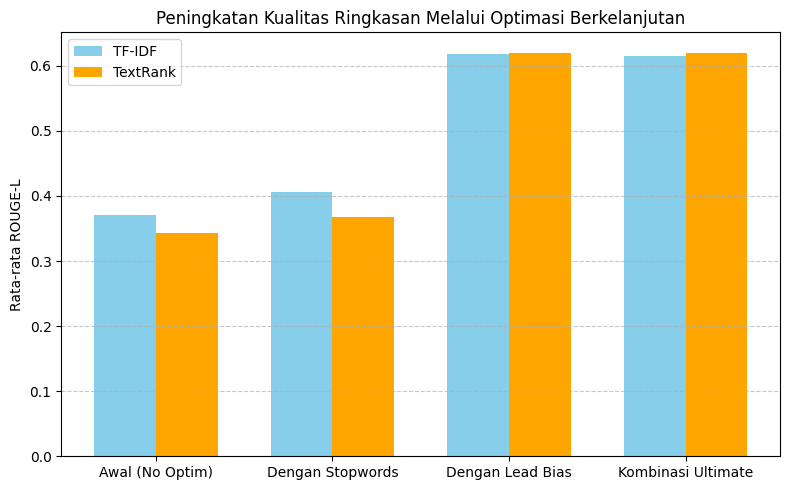

In [ ]:
import matplotlib.pyplot as plt

# Bandingkan hasil akhir visualisasi
models_compare = ['Awal (No Optim)', 'Dengan Stopwords', 'Dengan Lead Bias', 'Kombinasi Ultimate']
# Menggunakan data dari hasil eksperimen terdahulu dan saat ini
tfidf_scores = [0.3705, 0.4060, 0.6179, df_tfidf_ult.rougeL.mean()]
textrank_scores = [0.3435, 0.3678, 0.6204, df_tr_ult.rougeL.mean()]

x = np.arange(len(models_compare))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - width/2, tfidf_scores, width, label='TF-IDF', color='skyblue')
ax.bar(x + width/2, textrank_scores, width, label='TextRank', color='orange')

ax.set_ylabel('Rata-rata ROUGE-L')
ax.set_title('Peningkatan Kualitas Ringkasan Melalui Optimasi Berkelanjutan')
ax.set_xticks(x)
ax.set_xticklabels(models_compare)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

# **KESIMPULAN**

Pada eksperimen ini (IndoSum fold 01, 3.762 artikel uji), TF-IDF sedikit lebih baik daripada TextRank di semua metrik ROUGE untuk n = 1, 2, dan 3. ROUGE-L TF-IDF dengan stopword adalah 0,2927 / 0,3796 / 0,4060, sedangkan TextRank 0,2464 / 0,3329 / 0,3678. Skor naik seiring bertambahnya n karena ringkasan referensi IndoSum rata-rata terdiri dari sekitar 3 kalimat. Penghapusan stopword menaikkan ROUGE-L pada n = 3 dari 0,3705 menjadi 0,4060 (TF-IDF) dan dari 0,3435 menjadi 0,3678 (TextRank). Namun semua hasil itu masih jauh di bawah baseline Lead-3 (0,6220), karena berita di IndoSum menaruh informasi penting di awal artikel. Pembobotan posisi kalimat (decay 0,15) menaikkan ROUGE-L n = 3 menjadi 0,6179 (TF-IDF) dan 0,6204 (TextRank). Skor itu nyaris sama dengan Lead-3 tetapi tidak melampauinya. Menggabungkan stopword dan pembobotan posisi tidak menambah skor (0,6143 dan 0,6197). Jadi peningkatannya terutama karena model jadi lebih sering memilih kalimat awal, bukan karena lebih memahami isi artikel. Dengan pembobotan, TextRank sedikit di atas TF-IDF (selisih 0,0025), kebalikan dari kondisi tanpa pembobotan. Selisih sekecil itu dari satu kali evaluasi belum cukup untuk menyimpulkan metode mana yang lebih baik.

Pada 50 artikel uji, model abstraktif mT5 XL-Sum (tanpa fine-tuning) memperoleh ROUGE-L 0,4149. Skor ini hampir sama dengan TF-IDF n = 3 (0,4151) dan di atas TextRank n = 3 (0,3924). Tetapi mT5 butuh 1825 ms per artikel, sedangkan TF-IDF 2,65 ms dan TextRank 4,40 ms (n = 1). Dengan hanya 50 sampel, selisih ROUGE-L antar model terlalu kecil untuk dijadikan dasar kesimpulan. ROUGE juga hanya mencocokkan kata, jadi skor tinggi tidak otomatis berarti ringkasannya baik. Contoh terburuk menunjukkan kegagalan pemilihan kalimat: TF-IDF memilih daftar nama pemain (ROUGE-L 0,0000) dan TextRank memilih kalimat “” Enggak .” (0,0000). Karena itu, ringkasan sebaiknya dinilai dengan ROUGE dan pembacaan manual secara bersamaan.